In [1]:
import pandas as pd

In [2]:
customers=pd.read_csv("/content/customers.csv",encoding="latin1")

In [3]:
order_items=pd.read_csv("/content/order_items.csv",encoding="latin1")

In [4]:
orders=pd.read_csv("/content/orders.csv",encoding="latin1")

In [5]:
products=pd.read_csv("/content/products.csv",encoding="latin1")

In [6]:
customers

,customer_id,signup_date,state,acquisition_channel
0,1,2024-09-13,CO,organic_search
1,2,2025-10-21,IL,paid_search
2,3,2025-01-17,AZ,referral
3,4,2024-06-23,FL,paid_social
4,5,2025-04-08,IL,paid_social
...,...,...,...,...
3595,3596,2025-11-14,LA,referral
3596,3597,2025-05-27,WA,paid_search
3597,3598,2024-06-03,CA,paid_search
3598,3599,2025-08-23,LA,organic_search


In [7]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   customer_id          3600 non-null   int64 
 1   signup_date          3600 non-null   object
 2   state                3600 non-null   object
 3   acquisition_channel  3600 non-null   object
dtypes: int64(1), object(3)
memory usage: 112.6+ KB


In [8]:
customers.isnull().sum()

,0
customer_id,0
signup_date,0
state,0
acquisition_channel,0


In [9]:
customers.duplicated().sum()

np.int64(0)

In [10]:
customers["state"].unique()

array(['CO', 'IL', 'AZ', 'FL', 'OH', 'TX', 'WA', 'SC', 'CA', 'NY', 'UT',
       'LA', 'PA', 'GA', 'MD', 'KS', 'OK', 'MO', 'IA', 'NJ', 'MI', 'VA',
       'IN', 'CT', 'MN', 'OR', 'NM', 'NC', 'TN', 'KY', 'NV', 'MA', 'AL',
       'WI', 'AR'], dtype=object)

In [11]:
customers["acquisition_channel"].unique()

array(['organic_search', 'paid_search', 'referral', 'paid_social',
       'affiliate', 'email'], dtype=object)

In [12]:
customers["signup_date"]=pd.to_datetime(customers["signup_date"],format="mixed",errors="coerce")
customers["signup_date"].dtype

dtype('<M8[ns]')

In [13]:
orders

,order_id,customer_id,order_date,status,payment_method,discount_code,shipping_fee
0,100001,1530,2024-01-01 09:24:45,completed,credit_card,NaN,6.95
1,100002,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00
2,100003,840,2024-01-01 10:59:09,completed,credit_card,NaN,0.00
3,100004,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,0.00
4,100005,3452,2024-01-01 17:44:03,completed,gift_card,NaN,0.00
...,...,...,...,...,...,...,...
9240,109203,3499,2025-12-31 16:50:18,completed,credit_card,HOLIDAY20,6.95
9241,109204,3410,2025-12-31 17:40:58,completed,credit_card,HOLIDAY20,0.00
9242,109205,2911,2025-12-31 18:21:51,completed,credit_card,NaN,0.00
9243,109206,1157,2025-12-31 21:38:59,completed,credit_card,NaN,6.95


In [14]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9245 entries, 0 to 9244
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        9245 non-null   int64  
 1   customer_id     9245 non-null   int64  
 2   order_date      9245 non-null   object 
 3   status          9245 non-null   object 
 4   payment_method  9245 non-null   object 
 5   discount_code   1411 non-null   object 
 6   shipping_fee    9245 non-null   float64
dtypes: float64(1), int64(2), object(4)
memory usage: 505.7+ KB


In [15]:
orders.isnull().sum()

,0
order_id,0
customer_id,0
order_date,0
status,0
payment_method,0
discount_code,7834
shipping_fee,0


In [16]:
orders.duplicated().sum()

np.int64(38)

In [17]:
orders.drop_duplicates(inplace=True)
orders.duplicated().sum()

np.int64(0)

In [18]:
orders["discount_code"].value_counts(dropna=False)

,count
discount_code,
NaN,7802
HOLIDAY20,778
WELCOME10,389
SPRING15,238


In [19]:
orders.dtypes

,0
order_id,int64
customer_id,int64
order_date,object
status,object
payment_method,object
discount_code,object
shipping_fee,float64


In [20]:
orders["order_date"]=pd.to_datetime(orders["order_date"],errors="coerce")

In [21]:
orders["status"].unique()

array(['completed', 'returned', 'canceled'], dtype=object)

In [22]:
order_items

,order_id,product_id,quantity,unit_price,discount_amount
0,100001,1031,1,38.99,0.00
1,100002,1087,1,45.99,0.00
2,100002,1072,1,141.99,0.00
3,100003,1048,1,139.99,0.00
4,100004,1083,1,19.99,2.00
...,...,...,...,...,...
15603,109204,1070,1,129.14,25.83
15604,109205,1072,2,149.09,0.00
15605,109206,1071,1,10.49,0.00
15606,109207,1023,2,142.79,57.12


In [23]:
order_items.dtypes

,0
order_id,int64
product_id,int64
quantity,int64
unit_price,float64
discount_amount,float64


In [24]:
order_items.isnull().sum()

,0
order_id,0
product_id,0
quantity,0
unit_price,199
discount_amount,0


In [25]:
order_items[order_items["unit_price"].isnull()].head()

,order_id,product_id,quantity,unit_price,discount_amount
55,100033,1086,1,NaN,0.0
110,100062,1020,1,NaN,0.0
197,100116,1087,2,NaN,0.0
366,100210,1014,1,NaN,0.0
626,100361,1077,1,NaN,0.0


In [26]:
products

,product_id,product_name,category,list_price,unit_cost
0,1001,Brass Chef Knife,Kitchen,61.99,38.13
1,1002,Walnut Cutting Board,Kitchen,138.99,74.76
2,1003,Matte Black Dutch Oven,Kitchen,22.99,13.50
3,1004,Classic Skillet,Kitchen,75.99,39.86
4,1005,Linen Mixing Bowl Set,Kitchen,79.99,41.11
...,...,...,...,...,...
85,1086,Modern Under Bed Bin,Storage,97.99,43.62
86,1087,Cotton Pantry Container Set,Storage,45.99,20.30
87,1088,Coastal Coat Rack,Storage,20.99,12.03
88,1089,Modern Floating Shelf,Storage,53.99,24.22


In [27]:
products.dtypes

,0
product_id,int64
product_name,object
category,object
list_price,float64
unit_cost,float64


In [28]:
products.isnull().sum()

,0
product_id,0
product_name,0
category,0
list_price,0
unit_cost,0


In [29]:
products.duplicated().sum()

np.int64(0)

In [30]:
missing_unit_price=pd.merge(
    order_items,
    products,
    on="product_id",
    how="left"
    )
missing_unit_price

,order_id,product_id,quantity,unit_price,discount_amount,product_name,category,list_price,unit_cost
0,100001,1031,1,38.99,0.00,Stoneware Soap Dispenser,Bath,38.99,20.19
1,100002,1087,1,45.99,0.00,Cotton Pantry Container Set,Storage,45.99,20.30
2,100002,1072,1,141.99,0.00,Coastal Picture Frame Set,decor,141.99,62.78
3,100003,1048,1,139.99,0.00,Linen Loveseat,Furniture,139.99,71.41
4,100004,1083,1,19.99,2.00,Velvet Drawer Organizer,Storage,19.99,9.51
...,...,...,...,...,...,...,...,...,...
15603,109204,1070,1,129.14,25.83,Stoneware Wall Mirror,Decor,122.99,51.74
15604,109205,1072,2,149.09,0.00,Coastal Picture Frame Set,decor,141.99,62.78
15605,109206,1071,1,10.49,0.00,Oak Vase,Decor,9.99,5.84
15606,109207,1023,2,142.79,57.12,Linen Pillowcase Set,Bedding,135.99,60.49


In [31]:
missing_unit_price.isnull().sum()

,0
order_id,0
product_id,0
quantity,0
unit_price,199
discount_amount,0
product_name,0
category,0
list_price,0
unit_cost,0


In [32]:
missing_unit_price[missing_unit_price["unit_price"].isnull()].head()

,order_id,product_id,quantity,unit_price,discount_amount,product_name,category,list_price,unit_cost
55,100033,1086,1,NaN,0.0,Modern Under Bed Bin,Storage,97.99,43.62
110,100062,1020,1,NaN,0.0,Coastal Weighted Blanket,bedding,54.99,32.96
197,100116,1087,2,NaN,0.0,Cotton Pantry Container Set,Storage,45.99,20.30
366,100210,1014,1,NaN,0.0,Matte Black Stock Pot,Kitchen,36.99,18.86
626,100361,1077,1,NaN,0.0,Classic Table Runner,Decor,25.99,14.66


In [33]:
missing_unit_price["unit_price"].fillna(missing_unit_price["list_price"],inplace=True)

/tmp/ipykernel_6620/3334802165.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  missing_unit_price["unit_price"].fillna(missing_unit_price["list_price"],inplace=True)


In [34]:
missing_unit_price["unit_price"].isnull().sum()

np.int64(0)

In [35]:
missing_unit_price.duplicated().sum()

np.int64(0)

In [36]:
missing_unit_price.dtypes

,0
order_id,int64
product_id,int64
quantity,int64
unit_price,float64
discount_amount,float64
product_name,object
category,object
list_price,float64
unit_cost,float64


In [37]:
missing_unit_price.describe()

,order_id,product_id,quantity,unit_price,discount_amount,list_price,unit_cost
count,15608.000000,15608.000000,15608.000000,15608.000000,15608.000000,15608.000000,15608.000000
mean,104570.429011,1046.471040,1.244810,113.068473,3.201492,110.169459,56.245109
std,2659.674531,28.278148,0.577641,108.717917,11.154638,105.913996,58.551638
min,100001.000000,1001.000000,1.000000,7.990000,0.000000,7.990000,4.760000
25%,102269.750000,1020.000000,1.000000,49.990000,0.000000,49.990000,23.390000
50%,104554.500000,1048.000000,1.000000,86.090000,0.000000,85.990000,43.620000
75%,106867.250000,1073.000000,1.000000,139.990000,0.000000,135.990000,67.460000
max,109207.000000,1090.000000,4.000000,812.690000,196.560000,773.990000,445.470000


In [38]:
missing_unit_price["category"].unique()

array(['Bath', 'Storage', 'decor', 'Furniture', 'Storage ', ' Bedding',
       'LIGHTING', 'Kitchen', 'Decor', ' Kitchen', 'Furniture ',
       'Lighting', 'Bedding', 'Kitchen ', 'kitchen', 'Outdoor', 'BEDDING',
       'bath', 'bedding', 'furniture', 'KITCHEN', 'FURNITURE', 'OUTDOOR',
       ' Outdoor'], dtype=object)

In [39]:
missing_unit_price["category"]=missing_unit_price["category"].str.strip().str.upper()

In [40]:
missing_unit_price["category"].unique()

array(['BATH', 'STORAGE', 'DECOR', 'FURNITURE', 'BEDDING', 'LIGHTING',
       'KITCHEN', 'OUTDOOR'], dtype=object)

In [41]:
missing_unit_price["order_id"].isin(orders["order_id"]).all()

np.True_

In [42]:
missing_unit_price["product_id"].isin(products["product_id"]).all()

np.True_

In [43]:
missing_unit_price.shape

(15608, 9)

In [44]:
order_items.shape

(15608, 5)

In [45]:
missing_unit_price.describe()

,order_id,product_id,quantity,unit_price,discount_amount,list_price,unit_cost
count,15608.000000,15608.000000,15608.000000,15608.000000,15608.000000,15608.000000,15608.000000
mean,104570.429011,1046.471040,1.244810,113.068473,3.201492,110.169459,56.245109
std,2659.674531,28.278148,0.577641,108.717917,11.154638,105.913996,58.551638
min,100001.000000,1001.000000,1.000000,7.990000,0.000000,7.990000,4.760000
25%,102269.750000,1020.000000,1.000000,49.990000,0.000000,49.990000,23.390000
50%,104554.500000,1048.000000,1.000000,86.090000,0.000000,85.990000,43.620000
75%,106867.250000,1073.000000,1.000000,139.990000,0.000000,135.990000,67.460000
max,109207.000000,1090.000000,4.000000,812.690000,196.560000,773.990000,445.470000


In [46]:
oi=missing_unit_price

In [47]:
oi["total_price"]=oi["quantity"]*oi["unit_price"]
oi

,order_id,product_id,quantity,unit_price,discount_amount,product_name,category,list_price,unit_cost,total_price
0,100001,1031,1,38.99,0.00,Stoneware Soap Dispenser,BATH,38.99,20.19,38.99
1,100002,1087,1,45.99,0.00,Cotton Pantry Container Set,STORAGE,45.99,20.30,45.99
2,100002,1072,1,141.99,0.00,Coastal Picture Frame Set,DECOR,141.99,62.78,141.99
3,100003,1048,1,139.99,0.00,Linen Loveseat,FURNITURE,139.99,71.41,139.99
4,100004,1083,1,19.99,2.00,Velvet Drawer Organizer,STORAGE,19.99,9.51,19.99
...,...,...,...,...,...,...,...,...,...,...
15603,109204,1070,1,129.14,25.83,Stoneware Wall Mirror,DECOR,122.99,51.74,129.14
15604,109205,1072,2,149.09,0.00,Coastal Picture Frame Set,DECOR,141.99,62.78,298.18
15605,109206,1071,1,10.49,0.00,Oak Vase,DECOR,9.99,5.84,10.49
15606,109207,1023,2,142.79,57.12,Linen Pillowcase Set,BEDDING,135.99,60.49,285.58


In [48]:
oi["total_price"]=oi["total_price"]-oi["discount_amount"]
oi

,order_id,product_id,quantity,unit_price,discount_amount,product_name,category,list_price,unit_cost,total_price
0,100001,1031,1,38.99,0.00,Stoneware Soap Dispenser,BATH,38.99,20.19,38.99
1,100002,1087,1,45.99,0.00,Cotton Pantry Container Set,STORAGE,45.99,20.30,45.99
2,100002,1072,1,141.99,0.00,Coastal Picture Frame Set,DECOR,141.99,62.78,141.99
3,100003,1048,1,139.99,0.00,Linen Loveseat,FURNITURE,139.99,71.41,139.99
4,100004,1083,1,19.99,2.00,Velvet Drawer Organizer,STORAGE,19.99,9.51,17.99
...,...,...,...,...,...,...,...,...,...,...
15603,109204,1070,1,129.14,25.83,Stoneware Wall Mirror,DECOR,122.99,51.74,103.31
15604,109205,1072,2,149.09,0.00,Coastal Picture Frame Set,DECOR,141.99,62.78,298.18
15605,109206,1071,1,10.49,0.00,Oak Vase,DECOR,9.99,5.84,10.49
15606,109207,1023,2,142.79,57.12,Linen Pillowcase Set,BEDDING,135.99,60.49,228.46


In [49]:
oi[oi["discount_amount"]>oi['quantity']*oi["unit_price"]]

,order_id,product_id,quantity,unit_price,discount_amount,product_name,category,list_price,unit_cost,total_price


In [50]:
orders["customer_id"].isin(customers["customer_id"]).all()

np.True_

In [51]:
orders["status"].value_counts()

,count
status,
completed,8456
returned,407
canceled,344


In [52]:
customers

,customer_id,signup_date,state,acquisition_channel
0,1,2024-09-13,CO,organic_search
1,2,2025-10-21,IL,paid_search
2,3,2025-01-17,AZ,referral
3,4,2024-06-23,FL,paid_social
4,5,2025-04-08,IL,paid_social
...,...,...,...,...
3595,3596,2025-11-14,LA,referral
3596,3597,2025-05-27,WA,paid_search
3597,3598,2024-06-03,CA,paid_search
3598,3599,2025-08-23,LA,organic_search


In [53]:
orders

,order_id,customer_id,order_date,status,payment_method,discount_code,shipping_fee
0,100001,1530,2024-01-01 09:24:45,completed,credit_card,NaN,6.95
1,100002,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00
2,100003,840,2024-01-01 10:59:09,completed,credit_card,NaN,0.00
3,100004,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,0.00
4,100005,3452,2024-01-01 17:44:03,completed,gift_card,NaN,0.00
...,...,...,...,...,...,...,...
9240,109203,3499,2025-12-31 16:50:18,completed,credit_card,HOLIDAY20,6.95
9241,109204,3410,2025-12-31 17:40:58,completed,credit_card,HOLIDAY20,0.00
9242,109205,2911,2025-12-31 18:21:51,completed,credit_card,NaN,0.00
9243,109206,1157,2025-12-31 21:38:59,completed,credit_card,NaN,6.95


In [54]:
order_items

,order_id,product_id,quantity,unit_price,discount_amount
0,100001,1031,1,38.99,0.00
1,100002,1087,1,45.99,0.00
2,100002,1072,1,141.99,0.00
3,100003,1048,1,139.99,0.00
4,100004,1083,1,19.99,2.00
...,...,...,...,...,...
15603,109204,1070,1,129.14,25.83
15604,109205,1072,2,149.09,0.00
15605,109206,1071,1,10.49,0.00
15606,109207,1023,2,142.79,57.12


In [55]:
products

,product_id,product_name,category,list_price,unit_cost
0,1001,Brass Chef Knife,Kitchen,61.99,38.13
1,1002,Walnut Cutting Board,Kitchen,138.99,74.76
2,1003,Matte Black Dutch Oven,Kitchen,22.99,13.50
3,1004,Classic Skillet,Kitchen,75.99,39.86
4,1005,Linen Mixing Bowl Set,Kitchen,79.99,41.11
...,...,...,...,...,...
85,1086,Modern Under Bed Bin,Storage,97.99,43.62
86,1087,Cotton Pantry Container Set,Storage,45.99,20.30
87,1088,Coastal Coat Rack,Storage,20.99,12.03
88,1089,Modern Floating Shelf,Storage,53.99,24.22


In [56]:
cmpltd = orders[orders["status"] == "completed"]
cmpltd

,order_id,customer_id,order_date,status,payment_method,discount_code,shipping_fee
0,100001,1530,2024-01-01 09:24:45,completed,credit_card,NaN,6.95
1,100002,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00
2,100003,840,2024-01-01 10:59:09,completed,credit_card,NaN,0.00
3,100004,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,0.00
4,100005,3452,2024-01-01 17:44:03,completed,gift_card,NaN,0.00
...,...,...,...,...,...,...,...
9240,109203,3499,2025-12-31 16:50:18,completed,credit_card,HOLIDAY20,6.95
9241,109204,3410,2025-12-31 17:40:58,completed,credit_card,HOLIDAY20,0.00
9242,109205,2911,2025-12-31 18:21:51,completed,credit_card,NaN,0.00
9243,109206,1157,2025-12-31 21:38:59,completed,credit_card,NaN,6.95


In [57]:
oi

,order_id,product_id,quantity,unit_price,discount_amount,product_name,category,list_price,unit_cost,total_price
0,100001,1031,1,38.99,0.00,Stoneware Soap Dispenser,BATH,38.99,20.19,38.99
1,100002,1087,1,45.99,0.00,Cotton Pantry Container Set,STORAGE,45.99,20.30,45.99
2,100002,1072,1,141.99,0.00,Coastal Picture Frame Set,DECOR,141.99,62.78,141.99
3,100003,1048,1,139.99,0.00,Linen Loveseat,FURNITURE,139.99,71.41,139.99
4,100004,1083,1,19.99,2.00,Velvet Drawer Organizer,STORAGE,19.99,9.51,17.99
...,...,...,...,...,...,...,...,...,...,...
15603,109204,1070,1,129.14,25.83,Stoneware Wall Mirror,DECOR,122.99,51.74,103.31
15604,109205,1072,2,149.09,0.00,Coastal Picture Frame Set,DECOR,141.99,62.78,298.18
15605,109206,1071,1,10.49,0.00,Oak Vase,DECOR,9.99,5.84,10.49
15606,109207,1023,2,142.79,57.12,Linen Pillowcase Set,BEDDING,135.99,60.49,228.46


In [58]:
sales=pd.merge(
    oi,
    cmpltd,
    on="order_id",
    how="inner"
)

In [59]:
sales

,order_id,product_id,quantity,unit_price,discount_amount,product_name,category,list_price,unit_cost,total_price,customer_id,order_date,status,payment_method,discount_code,shipping_fee
0,100001,1031,1,38.99,0.00,Stoneware Soap Dispenser,BATH,38.99,20.19,38.99,1530,2024-01-01 09:24:45,completed,credit_card,NaN,6.95
1,100002,1087,1,45.99,0.00,Cotton Pantry Container Set,STORAGE,45.99,20.30,45.99,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00
2,100002,1072,1,141.99,0.00,Coastal Picture Frame Set,DECOR,141.99,62.78,141.99,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00
3,100003,1048,1,139.99,0.00,Linen Loveseat,FURNITURE,139.99,71.41,139.99,840,2024-01-01 10:59:09,completed,credit_card,NaN,0.00
4,100004,1083,1,19.99,2.00,Velvet Drawer Organizer,STORAGE,19.99,9.51,17.99,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14278,109204,1070,1,129.14,25.83,Stoneware Wall Mirror,DECOR,122.99,51.74,103.31,3410,2025-12-31 17:40:58,completed,credit_card,HOLIDAY20,0.00
14279,109205,1072,2,149.09,0.00,Coastal Picture Frame Set,DECOR,141.99,62.78,298.18,2911,2025-12-31 18:21:51,completed,credit_card,NaN,0.00
14280,109206,1071,1,10.49,0.00,Oak Vase,DECOR,9.99,5.84,10.49,1157,2025-12-31 21:38:59,completed,credit_card,NaN,6.95
14281,109207,1023,2,142.79,57.12,Linen Pillowcase Set,BEDDING,135.99,60.49,228.46,2208,2025-12-31 23:23:29,completed,paypal,HOLIDAY20,0.00


In [60]:
float(sales["total_price"].sum())

1881275.0799999998

In [61]:
cmpltd["shipping_fee"].sum()

np.float64(13135.5)

In [62]:
oi_revenue=sales["total_price"].sum()
shipping=cmpltd["shipping_fee"].sum()
total_revenue=oi_revenue+shipping
total_revenue

np.float64(1894410.5799999998)

In [63]:
cmpltd["order_date"].dt.year.value_counts()

,count
order_date,
2025,4589
2024,3867


In [64]:
sales_2024=sales[sales["order_date"].dt.year==2024]
revenue_2024=sales_2024["total_price"].sum()
shipping_2024=cmpltd[cmpltd["order_date"]==2024]["shipping_fee"].sum()
total_revenue=revenue_2024+shipping_2024
total_revenue


np.float64(850786.45)

In [65]:
sales_2025=sales[sales["order_date"].dt.year==2025]
revenue_2025=sales_2025["total_price"].sum()
shipping_2025=cmpltd[cmpltd["order_date"].dt.year==2025]["shipping_fee"].sum()
total_revenue_2025=revenue_2025+shipping_2025
total_revenue_2025

np.float64(1037556.78)

In [66]:
growth=total_revenue_2025-total_revenue
round(growth)

186770

In [67]:
growth_percentage=(growth/total_revenue)*100
round(growth_percentage)

22

In [68]:
sales["order_date"].dt.month

,order_date
0,1
1,1
2,1
3,1
4,1
...,...
14278,12
14279,12
14280,12
14281,12


In [69]:
sales["year_month"] = sales["order_date"].dt.to_period("M")

In [70]:
sales.groupby("year_month")["total_price"].sum()

,total_price
year_month,
2024-01,54389.51
2024-02,63274.62
2024-03,71769.38
2024-04,64768.74
2024-05,73652.84
2024-06,67205.38
2024-07,77269.04
2024-08,62683.57
2024-09,60054.02


In [71]:
monthly_shipping=cmpltd.groupby(cmpltd["order_date"].dt.to_period("M"))["shipping_fee"].sum()
monthly_shipping

,shipping_fee
order_date,
2024-01,430.90
2024-02,375.30
2024-03,417.00
2024-04,465.65
2024-05,403.10
2024-06,403.10
2024-07,423.95
2024-08,458.70
2024-09,396.15


In [72]:
monthly_revenue = sales.groupby("year_month")["total_price"].sum()

monthly_total_revenue = (
    monthly_revenue.add(monthly_shipping, fill_value=0)
)

monthly_total_revenue

,0
year_month,
2024-01,54820.41
2024-02,63649.92
2024-03,72186.38
2024-04,65234.39
2024-05,74055.94
2024-06,67608.48
2024-07,77692.99
2024-08,63142.27
2024-09,60450.17


In [73]:
monthly_comparison = monthly_total_revenue.to_frame(
    name="total_revenue"
)

monthly_comparison["year"] = (
    monthly_comparison.index.year
)

monthly_comparison["month"] = (
    monthly_comparison.index.month
)

monthly_comparison

,total_revenue,year,month
year_month,,,
2024-01,54820.41,2024,1
2024-02,63649.92,2024,2
2024-03,72186.38,2024,3
2024-04,65234.39,2024,4
2024-05,74055.94,2024,5
2024-06,67608.48,2024,6
2024-07,77692.99,2024,7
2024-08,63142.27,2024,8
2024-09,60450.17,2024,9


In [74]:
revenue_pivot=pd.pivot_table(
    monthly_comparison,
    index="month",
    columns="year",
    values="total_revenue"
)

In [80]:
category_revenue=sales.groupby("category")["total_price"].sum().sort_values(ascending=False)
category_revenue

,total_price
category,
FURNITURE,322774.21
KITCHEN,279719.21
DECOR,277848.70
BEDDING,266931.61
OUTDOOR,247612.23
LIGHTING,237737.13
STORAGE,139648.40
BATH,109003.59


In [83]:
top_10_products=(sales.groupby("product_name")["total_price"].sum().sort_values(ascending=False).head(10))
top_10_products

,total_price
product_name,
Cotton Patio Chair,67034.90
Classic Dining Chair Pair,52017.94
Coastal Picture Frame Set,44213.96
Ceramic Quilt,41379.17
Bamboo Nightstand,41339.23
Modern Wreath,40995.15
Nordic Side Table,40366.49
Velvet String Lights,38803.92
Classic Garland,38667.93


In [89]:
total_orders=orders["order_id"].count()
total_orders

np.int64(9207)

In [90]:
rtrnd=orders[orders["status"]=="returned"]
rtrnd

,order_id,customer_id,order_date,status,payment_method,discount_code,shipping_fee
6,100007,1891,2024-01-01 23:25:28,returned,credit_card,NaN,0.00
20,100021,3260,2024-01-02 21:33:19,returned,paypal,NaN,0.00
43,100044,2115,2024-01-06 14:02:48,returned,credit_card,NaN,0.00
46,100047,1891,2024-01-06 16:09:46,returned,paypal,NaN,0.00
53,100054,3057,2024-01-06 20:55:56,returned,paypal,NaN,0.00
...,...,...,...,...,...,...,...
9130,109093,2022,2025-12-22 14:17:17,returned,paypal,HOLIDAY20,6.95
9144,109107,3306,2025-12-23 10:48:53,returned,paypal,HOLIDAY20,0.00
9158,109121,1061,2025-12-24 11:43:17,returned,credit_card,NaN,0.00
9187,109150,909,2025-12-27 16:39:04,returned,paypal,NaN,0.00


In [140]:
rtrnd_percent=(len(rtrnd)/total_orders)*100
print(rtrnd_percent)

4.4205495818399045


In [95]:
cncld=orders[orders["status"]=="canceled"]
cncld

,order_id,customer_id,order_date,status,payment_method,discount_code,shipping_fee
48,100049,1375,2024-01-06 16:41:03,canceled,paypal,NaN,0.00
66,100067,738,2024-01-07 20:33:48,canceled,apple_pay,NaN,0.00
81,100082,511,2024-01-09 15:33:06,canceled,apple_pay,NaN,0.00
89,100090,2409,2024-01-10 17:36:56,canceled,apple_pay,NaN,0.00
97,100098,2652,2024-01-11 15:04:07,canceled,credit_card,NaN,0.00
...,...,...,...,...,...,...,...
9080,109044,2721,2025-12-19 09:08:21,canceled,credit_card,HOLIDAY20,0.00
9116,109080,2867,2025-12-21 18:22:05,canceled,credit_card,HOLIDAY20,0.00
9173,109136,1071,2025-12-25 21:30:03,canceled,credit_card,NaN,0.00
9178,109141,2911,2025-12-26 16:11:45,canceled,credit_card,NaN,0.00


In [141]:
cncld_percent=(len(cncld)/total_orders)*100
print(cncld_percent)

3.7362876072553495


In [142]:
a=(cmpltd["order_date"].dt.year==2024).sum()
print(a)

3867


In [143]:
avg_order_2024=total_revenue/a
print(round(avg_order_2024))

220


In [144]:
b=(cmpltd["order_date"].dt.year==2025).sum()
print(b)

4589


In [145]:
avg_order_2025=total_revenue_2025/b
print(round(avg_order_2025))

226


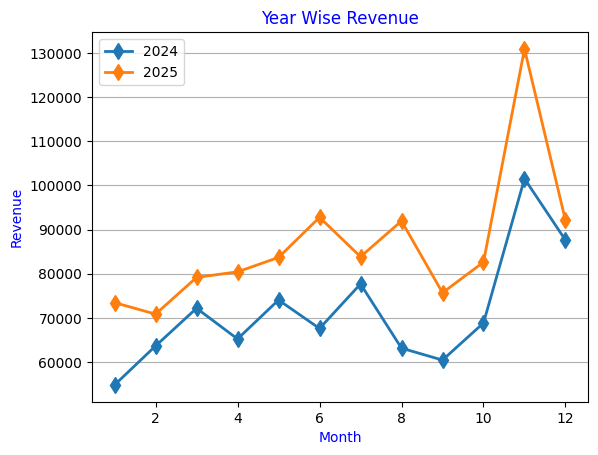

In [146]:
from matplotlib.lines import lineStyles
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
ax.plot(revenue_pivot.index,revenue_pivot[2024],marker="d",markersize=8,linestyle="solid",linewidth=2,label=2024)
ax.plot(revenue_pivot.index,revenue_pivot[2025],marker="d",markersize=8,linestyle="solid",linewidth=2,label=2025)
ax.set_xlabel("Month",color="Blue")
ax.set_ylabel("Revenue",color="Blue")
ax.set_title("Year Wise Revenue",color="Blue")
ax.legend()
ax.grid(axis="y")
plt.show()

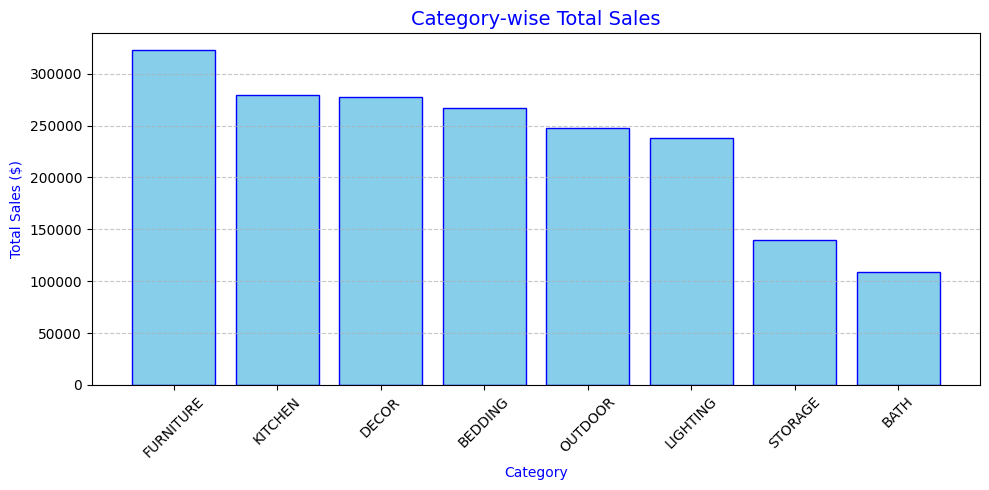

In [147]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 5))
# Passing both categories (x) and heights (y) to ax.bar()
ax.bar(category_revenue.index, category_revenue.values, color='skyblue', edgecolor='blue')
ax.set_xlabel("Category", color="Blue")
ax.set_ylabel("Total Sales ($)", color="Blue")
ax.set_title("Category-wise Total Sales", color="Blue", fontsize=14)
ax.grid(axis="y", linestyle="--", alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

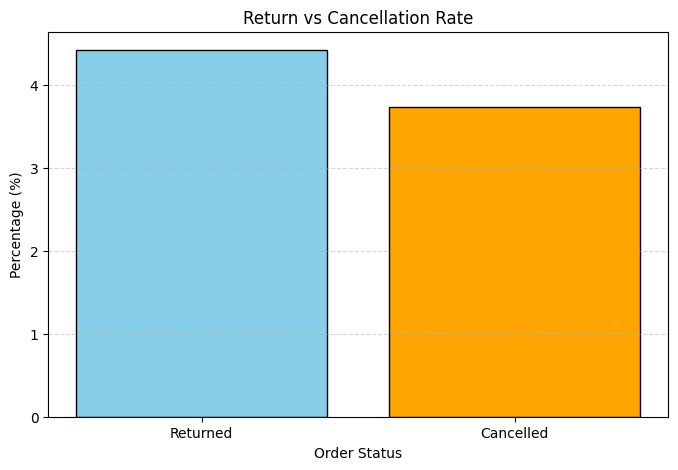

In [148]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    ["Returned", "Cancelled"],
    [rtrnd_percent, cncld_percent],
    color=["skyblue", "orange"],
    edgecolor="black"
)

ax.set_title("Return vs Cancellation Rate")
ax.set_xlabel("Order Status")
ax.set_ylabel("Percentage (%)")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()